# TUGAS BESAR 1: JARINGAN SYARAF TIRUAN (IT6053)
## Analisis dan Implementasi Klasifikasi Data Menggunakan Perceptron dan ADALINE

**Identitas Kelompok: Kelompok 09**
1. **Fransina Riyanty Batlayar** - 71231014
2. **Amelia Agustin** - 71231038
3. **Nengah Yesi Putri** - 71231047
4. **Samuel Natanael** - 71231050

**Program Studi Informatika | Fakultas Teknologi Informasi | Universitas Kristen Duta Wacana**  
**Tahun Akademik 2026/2027**

---
## 1. Pemahaman Kasus dan Dataset (Kesinambungan Tugas 1)

### 1.1 Latar Belakang Masalah
Pada Tugas 1, kami menganalisis opini masyarakat di media sosial terkait implementasi program nasional **Makan Bergizi Gratis (MBG)**. Isu ini memicu perdebatan publik yang sangat luas, mulai dari apresiasi atas peningkatan nutrisi anak sekolah hingga kritik tajam mengenai tata kelola, transparansi anggaran, dan kualitas gizi makanan.

Tujuan dari studi kasus ini adalah membangun model klasifikasi otomatis yang mampu membedakan opini publik menjadi dua kelas:
- **Kelas +1 (Sentimen Positif)**: Komentar yang berisi dukungan, apresiasi, harapan, dan manfaat program MBG.
- **Kelas -1 (Sentimen Negatif)**: Komentar yang berisi kritik, keluhan kualitas makanan, kekhawatiran korupsi, atau penolakan.

### 1.2 Deskripsi dan Karakteristik Dataset
Dataset bersumber dari hasil ekstraksi (*crawling*) komentar publik pada platform media sosial (YouTube) menggunakan kata kunci terkait MBG pada periode awal tahun 2026.
- **Jumlah Observasi Mentah**: 6.419 komentar.
- **Hasil Pelabelan Biner**: 2.012 komentar memiliki polaritas yang jelas (1.045 Positif dan 967 Negatif), sedangkan komentar netral/ambigu disaring.
- **Fitur Numerik yang Digunakan**:
  1. `pos_score`: Frekuensi kemunculan kata-kata berbobot leksikon positif (misal: *bagus, berkah, gizi, sehat, dukung, alhamdulillah*).
  2. `neg_score`: Frekuensi kemunculan kata-kata berbobot leksikon negatif (misal: *korupsi, maling, rusak, racun, kecewa, biadab*).
  Fitur ini sangat representatif untuk merefleksikan kecenderungan polaritas teks secara terukur dan memungkinkan visualisasi batas keputusan (*decision boundary*) pada ruang 2D.

---
## 2. Pemuatan dan Pra-pengolahan Data
Data dimuat dari file `dataset.csv`. Kemudian dilakukan pembagian data latih (*training*) dan data uji (*testing*) dengan rasio **80:20** menggunakan metode stratifikasi (*stratified split*) dan `random_state = 42` agar distribusi kelas seimbang pada kedua subset.
Standardisasi fitur dilakukan dengan `StandardScaler` di mana parameter $\mu$ dan $\sigma$ **hanya dipelajari dari data latih** untuk mencegah kebocoran data (*data leakage*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Pemuatan Dataset
df = pd.read_csv('dataset.csv')
print("Informasi Dataset:")
print(f"Total baris: {len(df)}")
print(f"Distribusi Target Label:\n{df['label'].value_counts()}")
df.head()

Informasi Dataset:
Total baris: 2012
Distribusi Target Label:
label
 1    1045
-1     967
Name: count, dtype: int64


,author,like_count,text_length,pos_score,neg_score,clean_text,label
0,@fakhrieofisial4819,0,23,0,4,rusak lah negara kalau nepotisme korupsi semak...,-1
1,@sudaryadidar1358,0,17,0,3,programpresiden jokowi berobat gratid banyak p...,-1
2,@santanasa7179,0,4,0,1,ganti makan racun gratis,-1
3,@sanesane1483,1,12,1,0,alhamdulillah makasihh proyek mbg saya jadi ad...,1
4,@priyoidn2759,0,5,0,1,mbg menu bancakan ala gerinda,-1


In [2]:
# 2. Pemilihan Fitur dan Target
# Fitur yang digunakan: pos_score dan neg_score (2 dimensi untuk analisis dan visualisasi decision boundary)
X = df[['pos_score', 'neg_score']].values
y = df['label'].values

# 3. Pembagian Data (Train 80% : Test 20%) dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Jumlah sampel Train: {len(X_train)} (Positif: {np.sum(y_train == 1)}, Negatif: {np.sum(y_train == -1)})")
print(f"Jumlah sampel Test : {len(X_test)} (Positif: {np.sum(y_test == 1)}, Negatif: {np.sum(y_test == -1)})")

# 4. Standardisasi Fitur (Hanya fit pada X_train)
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print(f"Mean Train Fitur: {scaler.mean_}")
print(f"Std  Train Fitur: {scaler.scale_}")

Jumlah sampel Train: 1609 (Positif: 836, Negatif: 773)
Jumlah sampel Test : 403 (Positif: 209, Negatif: 194)
Mean Train Fitur: [0.76444997 0.63642014]
Std  Train Fitur: [0.92265409 0.77975701]


---
## 3. Model Neuron dan Perhitungan Manual

### 3.1 Formulasi Matematis Model
1. **Net Input (Keluaran Linear)**:
   $$z = \mathbf{w}^T \mathbf{x} + b = \sum_{j=1}^{m} w_j x_j + b$$

2. **Fungsi Aktivasi dan Keputusan**:
   - Prediksi biner:
     $$\hat{y} = \begin{cases} +1, & \text{jika } z \ge 0 \\ -1, & \text{jika } z < 0 \end{cases}$$

3. **Aturan Pembelajaran Perceptron (Rosenblatt)**:
   - Evaluasi sampel per sampel secara sekuensial.
   - Pembaruan hanya terjadi jika terjadi salah klasifikasi ($y^{(i)} \neq \hat{y}^{(i)}$):
     $$\Delta = \alpha (y^{(i)} - \hat{y}^{(i)})$$
     $$\mathbf{w} \leftarrow \mathbf{w} + \Delta \mathbf{x}^{(i)}$$
     $$b \leftarrow b + \Delta$$

4. **Aturan Pembelajaran ADALINE (Delta Rule / Widrow-Hoff)**:
   - Error dihitung dari keluaran linear kontinu $z$, bukan dari fungsi ambang:
     $$e^{(i)} = y^{(i)} - z^{(i)}$$
   - Fungsi objektif (Mean Squared Error):
     $$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y^{(i)} - z^{(i)})^2, \quad J(\mathbf{w}, b) = \frac{1}{2n} \sum_{i=1}^{n} (y^{(i)} - z^{(i)})^2$$
   - Pembaruan menggunakan Batch Gradient Descent:
     $$\mathbf{w} \leftarrow \mathbf{w} + \alpha \frac{\mathbf{X}^T \mathbf{e}}{n}$$
     $$b \leftarrow b + \alpha \cdot \text{mean}(\mathbf{e})$$

---
### 3.2 Contoh Perhitungan Manual (2 Langkah)

#### A. Perhitungan Manual Perceptron (2 Sampel Pertama)
Misalkan inisialisasi awal $\mathbf{w} = [0.0, 0.0]^T$, $b = 0.0$, dan laju pembelajaran $\alpha = 0.01$.

- **Sampel 1**: Misal $\mathbf{x}^{(1)} = [2.0, 0.0]$, label target $y^{(1)} = +1$.
  - Net input: $z = 0(2.0) + 0(0.0) + 0 = 0.0$.
  - Prediksi: Karena $z \ge 0$, maka $\hat{y} = +1$.
  - Error: $y^{(1)} - \hat{y}^{(1)} = 1 - 1 = 0$ (Klasifikasi Benar).
  - Tidak ada pembaruan: $\mathbf{w}^{(1)} = [0.0, 0.0]^T$, $b^{(1)} = 0.0$.

- **Sampel 2**: Misal $\mathbf{x}^{(2)} = [0.0, 3.0]$, label target $y^{(2)} = -1$.
  - Net input: $z = 0(0.0) + 0(3.0) + 0 = 0.0$.
  - Prediksi: Karena $z \ge 0$, maka $\hat{y} = +1$.
  - Error: $y^{(2)} - \hat{y}^{(2)} = -1 - (+1) = -2$ (Salah Klasifikasi!).
  - Pembaruan parameter:
    $$\Delta = \alpha (y - \hat{y}) = 0.01 \times (-2) = -0.02$$
    $$\mathbf{w}^{(2)} = \mathbf{w}^{(1)} + \Delta \mathbf{x}^{(2)} = [0.0, 0.0]^T + (-0.02)[0.0, 3.0]^T = [0.0, -0.06]^T$$
    $$b^{(2)} = b^{(1)} + \Delta = 0.0 + (-0.02) = -0.02$$

#### B. Perhitungan Manual ADALINE (2 Iterasi Batch)
Misalkan dataset mini berisi 2 sampel:
- Sampel 1: $\mathbf{x}^{(1)} = [1.0, -1.0]$, target $y^{(1)} = 1$
- Sampel 2: $\mathbf{x}^{(2)} = [-1.0, 1.0]$, target $y^{(2)} = -1$
Inisialisasi awal: $\mathbf{w} = [0.0, 0.0]^T$, $b = 0.0$, dan $\alpha = 0.1$.

- **Iterasi 1**:
  - $z^{(1)} = 0$, $z^{(2)} = 0$
  - Error: $e^{(1)} = 1 - 0 = 1.0$, $e^{(2)} = -1 - 0 = -1.0$
  - $\mathbf{X}^T \mathbf{e} = [1.0(1.0) + (-1.0)(-1.0), \, -1.0(1.0) + 1.0(-1.0)]^T = [2.0, -2.0]^T$
  - Rata-rata gradien bobot: $\frac{1}{2} \mathbf{X}^T \mathbf{e} = [1.0, -1.0]^T$
  - Rata-rata error bias: $\text{mean}(\mathbf{e}) = \frac{1 + (-1)}{2} = 0.0$
  - Pembaruan:
    $$\mathbf{w} \leftarrow [0.0, 0.0]^T + 0.1 [1.0, -1.0]^T = [0.1, -0.1]^T$$
    $$b \leftarrow 0.0 + 0.1 (0.0) = 0.0$$
  - $\text{MSE}_{1} = \frac{1^2 + (-1)^2}{2} = 1.0$

- **Iterasi 2**:
  - Dengan $\mathbf{w} = [0.1, -0.1]^T$, $b = 0.0$:
  - $z^{(1)} = 0.1(1.0) + (-0.1)(-1.0) + 0 = 0.2$
  - $z^{(2)} = 0.1(-1.0) + (-0.1)(1.0) + 0 = -0.2$
  - Error: $e^{(1)} = 1 - 0.2 = 0.8$, $e^{(2)} = -1 - (-0.2) = -0.8$
  - $\mathbf{X}^T \mathbf{e} = [1.0(0.8) + (-1.0)(-0.8), \, -1.0(0.8) + 1.0(-0.8)]^T = [1.6, -1.6]^T$
  - Rata-rata gradien: $\frac{1}{2} \mathbf{X}^T \mathbf{e} = [0.8, -0.8]^T$
  - Pembaruan:
    $$\mathbf{w} \leftarrow [0.1, -0.1]^T + 0.1 [0.8, -0.8]^T = [0.18, -0.18]^T$$
    $$b \leftarrow 0.0 + 0.1(0.0) = 0.0$$
  - $\text{MSE}_{2} = \frac{0.8^2 + (-0.8)^2}{2} = 0.64$ (Error berkurang dari 1.0 menjadi 0.64, menunjukkan konvergensi).

---
## 4. Implementasi Mandiri Perceptron dan ADALINE (Python & NumPy)
Berikut adalah implementasi kedua model dari dasar (*from scratch*) tanpa menggunakan fungsi pelatihan pustaka siap pakai.

In [3]:
class PerceptronNumPy:
    """
    Implementasi Perceptron Klasik (Rosenblatt, 1958)
    """
    def __init__(self, learning_rate=0.01, epochs=50):
        self.lr = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None
        self.errors_per_epoch = []
        self.history = {}

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.errors_per_epoch = []

        for epoch in range(1, self.epochs + 1):
            misclassifications = 0
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.w) + self.b
                y_pred = 1 if linear_output >= 0.0 else -1
                
                # Update rule saat terjadi salah klasifikasi
                if y[idx] != y_pred:
                    update = self.lr * (y[idx] - y_pred)
                    self.w += update * x_i
                    self.b += update
                    misclassifications += 1

            self.errors_per_epoch.append(misclassifications)
            if epoch in [10, 30, 50]:
                self.history[epoch] = {
                    'w': self.w.copy(),
                    'b': self.b,
                    'errors': misclassifications
                }
        return self

    def predict(self, X):
        linear_output = np.dot(X, self.w) + self.b
        return np.where(linear_output >= 0.0, 1, -1)

In [4]:
class AdalineGD:
    """
    Implementasi ADALINE (Widrow & Hoff, 1960) dengan Batch Gradient Descent
    """
    def __init__(self, learning_rate=0.01, epochs=50):
        self.lr = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None
        self.mse_per_epoch = []
        self.history = {}

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.mse_per_epoch = []

        for epoch in range(1, self.epochs + 1):
            linear_output = np.dot(X, self.w) + self.b
            errors = y - linear_output
            
            # Hitung MSE sebelum/saat pembaruan
            mse = np.mean(errors ** 2)
            self.mse_per_epoch.append(mse)

            # Deteksi divergensi numerik jika loss meledak
            if np.isnan(mse) or np.isinf(mse):
                print(f"[Peringatan] Divergensi numerik / NaN terdeteksi pada epoch {epoch}!")
                break

            # Batch Gradient Descent update
            self.w += self.lr * (np.dot(X.T, errors) / n_samples)
            self.b += self.lr * np.mean(errors)

            if epoch in [10, 30, 50]:
                self.history[epoch] = {
                    'w': self.w.copy(),
                    'b': self.b,
                    'mse': mse
                }
        return self

    def predict(self, X):
        linear_output = np.dot(X, self.w) + self.b
        return np.where(linear_output >= 0.0, 1, -1)

---
## 5. Eksperimen dan Hasil Evaluasi (8 Konfigurasi Utama)
Sesuai dengan ketentuan rubrik penugasan, kami menjalankan **8 konfigurasi eksperimen**:
1. Tiga konfigurasi Perceptron dengan standardisasi ($\alpha \in \{0.001, 0.01, 0.1\}$)
2. Satu konfigurasi Perceptron tanpa standardisasi ($\alpha = 0.01$)
3. Tiga konfigurasi ADALINE dengan standardisasi ($\alpha \in \{0.001, 0.01, 0.1\}$)
4. Satu konfigurasi ADALINE tanpa standardisasi ($\alpha = 0.01$)
Seluruh pengujian dijalankan selama **50 epoch** dengan data pembagian dan urutan sampel yang terkontrol.

In [5]:
# Daftar Skenario Eksperimen
experiments = [
    # Perceptron
    {'model_type': 'Perceptron', 'lr': 0.001, 'epochs': 50, 'std': True},
    {'model_type': 'Perceptron', 'lr': 0.01,  'epochs': 50, 'std': True},
    {'model_type': 'Perceptron', 'lr': 0.1,   'epochs': 50, 'std': True},
    {'model_type': 'Perceptron', 'lr': 0.01,  'epochs': 50, 'std': False},
    # ADALINE
    {'model_type': 'ADALINE',    'lr': 0.001, 'epochs': 50, 'std': True},
    {'model_type': 'ADALINE',    'lr': 0.01,  'epochs': 50, 'std': True},
    {'model_type': 'ADALINE',    'lr': 0.1,   'epochs': 50, 'std': True},
    {'model_type': 'ADALINE',    'lr': 0.01,  'epochs': 50, 'std': False},
]

results = []
trained_models = []

for exp in experiments:
    # Tentukan data yang digunakan (Standardisasi vs Asli)
    if exp['std']:
        X_tr = X_train_std
        X_te = X_test_std
    else:
        X_tr = X_train
        X_te = X_test

    # Inisialisasi dan pelatihan model
    if exp['model_type'] == 'Perceptron':
        model = PerceptronNumPy(learning_rate=exp['lr'], epochs=exp['epochs'])
        model.fit(X_tr, y_train)
        final_loss = model.errors_per_epoch[-1] if len(model.errors_per_epoch) > 0 else np.nan
    else:
        model = AdalineGD(learning_rate=exp['lr'], epochs=exp['epochs'])
        model.fit(X_tr, y_train)
        final_loss = model.mse_per_epoch[-1] if len(model.mse_per_epoch) > 0 else np.nan

    trained_models.append(model)

    # Evaluasi Prediksi
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)

    acc_tr = accuracy_score(y_train, y_pred_tr)
    acc_te = accuracy_score(y_test, y_pred_te)

    # Bobot akhir
    w_str = f"[{model.w[0]:.4f}, {model.w[1]:.4f}]" if model.w is not None else "NaN"
    b_str = f"{model.b:.4f}" if model.b is not None else "NaN"

    results.append({
        'Model': exp['model_type'],
        'Alpha (α)': exp['lr'],
        'Epoch': exp['epochs'],
        'Standardisasi': 'Ya' if exp['std'] else 'Tidak',
        'Akurasi Latih (%)': round(acc_tr * 100, 2),
        'Akurasi Uji (%)': round(acc_te * 100, 2),
        'Final Error/Loss': round(final_loss, 4) if not np.isnan(final_loss) else 'Divergen',
        'Bobot Akhir (w)': w_str,
        'Bias Akhir (b)': b_str
    })

# Tampilkan Tabel Hasil
df_results = pd.DataFrame(results)
display(df_results)

,Model,Alpha (α),Epoch,Standardisasi,Akurasi Latih (%),Akurasi Uji (%),Final Error/Loss,Bobot Akhir (w),Bias Akhir (b)
0,Perceptron,0.001,50,Ya,100.0,100.0,0.0000,"[0.0022, -0.0026]",0.0000
1,Perceptron,0.010,50,Ya,100.0,100.0,0.0000,"[0.0217, -0.0256]",0.0000
2,Perceptron,0.100,50,Ya,100.0,100.0,0.0000,"[0.2168, -0.2565]",0.0000
3,Perceptron,0.010,50,Tidak,100.0,100.0,0.0000,"[0.1000, -0.0800]",-0.0200
4,ADALINE,0.001,50,Ya,100.0,100.0,0.8943,"[0.0353, -0.0380]",0.0019
5,ADALINE,0.010,50,Ya,100.0,100.0,0.3932,"[0.2596, -0.2829]",0.0155
6,ADALINE,0.100,50,Ya,100.0,100.0,0.2019,"[0.4769, -0.5683]",0.0390
7,ADALINE,0.010,50,Tidak,100.0,100.0,0.4900,"[0.2602, -0.2422]",0.0040


---
## 6. Pemantauan Riwayat Pelatihan (Epoch 10, 30, dan 50)
Sesuai panduan evaluasi, berikut adalah catatan status bobot, bias, dan nilai error/loss pada checkpoint epoch ke-10, ke-30, dan ke-50.

In [6]:
checkpoint_data = []

for idx, exp in enumerate(experiments):
    model = trained_models[idx]
    config_name = f"{exp['model_type']} (α={exp['lr']}, Std={'Ya' if exp['std'] else 'Tidak'})"
    
    for ep in [10, 30, 50]:
        if ep in model.history:
            h = model.history[ep]
            w_val = f"[{h['w'][0]:.4f}, {h['w'][1]:.4f}]"
            b_val = f"{h['b']:.4f}"
            metric = h.get('errors', h.get('mse', None))
            checkpoint_data.append({
                'Konfigurasi': config_name,
                'Epoch': ep,
                'Bobot (w)': w_val,
                'Bias (b)': b_val,
                'Error / MSE': round(metric, 4) if metric is not None else 'NaN'
            })

df_checkpoints = pd.DataFrame(checkpoint_data)
display(df_checkpoints.head(15))

,Konfigurasi,Epoch,Bobot (w),Bias (b),Error / MSE
0,"Perceptron (α=0.001, Std=Ya)",10,"[0.0022, -0.0026]",0.0000,0.0000
1,"Perceptron (α=0.001, Std=Ya)",30,"[0.0022, -0.0026]",0.0000,0.0000
2,"Perceptron (α=0.001, Std=Ya)",50,"[0.0022, -0.0026]",0.0000,0.0000
3,"Perceptron (α=0.01, Std=Ya)",10,"[0.0217, -0.0256]",0.0000,0.0000
4,"Perceptron (α=0.01, Std=Ya)",30,"[0.0217, -0.0256]",0.0000,0.0000
5,"Perceptron (α=0.01, Std=Ya)",50,"[0.0217, -0.0256]",0.0000,0.0000
6,"Perceptron (α=0.1, Std=Ya)",10,"[0.2168, -0.2565]",0.0000,0.0000
7,"Perceptron (α=0.1, Std=Ya)",30,"[0.2168, -0.2565]",0.0000,0.0000
8,"Perceptron (α=0.1, Std=Ya)",50,"[0.2168, -0.2565]",0.0000,0.0000
9,"Perceptron (α=0.01, Std=Tidak)",10,"[0.1000, -0.0800]",-0.0200,0.0000


---
## 7. Visualisasi Kurva Pembelajaran (Learning Curves)
Berikut ditampilkan grafik perbandingan konvergensi:
1. **Kurva Perceptron**: Jumlah sampel salah klasifikasi (*misclassifications*) per epoch.
2. **Kurva ADALINE**: Nilai *Mean Squared Error* (MSE) per epoch.

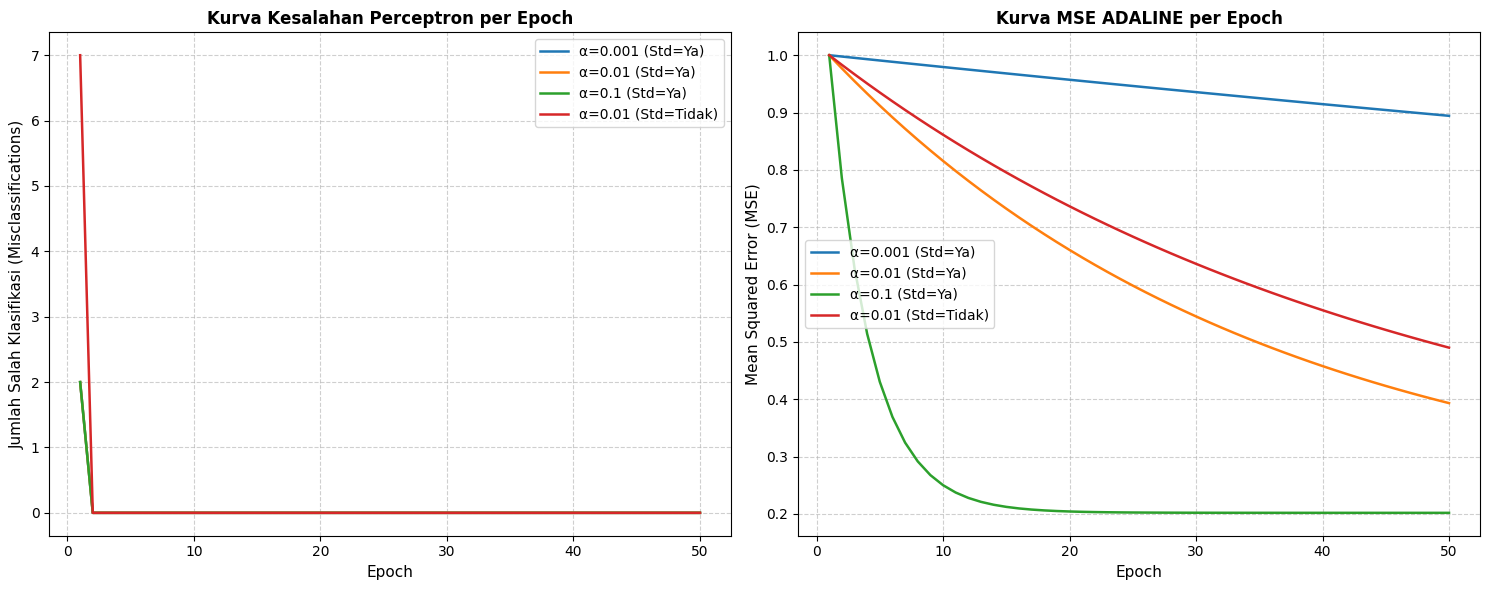

In [7]:
plt.figure(figsize=(15, 6))

# Plot 1: Perceptron Misclassifications
plt.subplot(1, 2, 1)
for idx in [0, 1, 2, 3]:
    exp = experiments[idx]
    model = trained_models[idx]
    label_txt = f"α={exp['lr']} (Std={'Ya' if exp['std'] else 'Tidak'})"
    plt.plot(range(1, len(model.errors_per_epoch) + 1), model.errors_per_epoch, label=label_txt, lw=1.8)

plt.title('Kurva Kesalahan Perceptron per Epoch', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Jumlah Salah Klasifikasi (Misclassifications)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: ADALINE MSE
plt.subplot(1, 2, 2)
for idx in [4, 5, 6, 7]:
    exp = experiments[idx]
    model = trained_models[idx]
    label_txt = f"α={exp['lr']} (Std={'Ya' if exp['std'] else 'Tidak'})"
    # Batasi jika loss terlalu besar agar tidak merusak skala grafik
    losses = [l if l < 10 else 10 for l in model.mse_per_epoch]
    plt.plot(range(1, len(losses) + 1), losses, label=label_txt, lw=1.8)

plt.title('Kurva MSE ADALINE per Epoch', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Mean Squared Error (MSE)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

---
## 8. Confusion Matrix dan Metrik Evaluasi pada Data Uji
Untuk konfigurasi terbaik ($\alpha = 0.01$ dengan Standardisasi), kita evaluasi **Confusion Matrix**, **Precision**, **Recall**, dan **F1-Score** pada data uji.

C:\Users\Samuel Natanael\AppData\Local\Temp\ipykernel_8644\694546651.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
C:\Users\Samuel Natanael\AppData\Local\Temp\ipykernel_8644\694546651.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_yticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
C:\Users\Samuel Natanael\AppData\Local\Temp\ipykernel_8644\694546651.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
C:\Users\Samuel Natanael\AppData\Local\Temp\ipykernel_8644\694546651.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedL

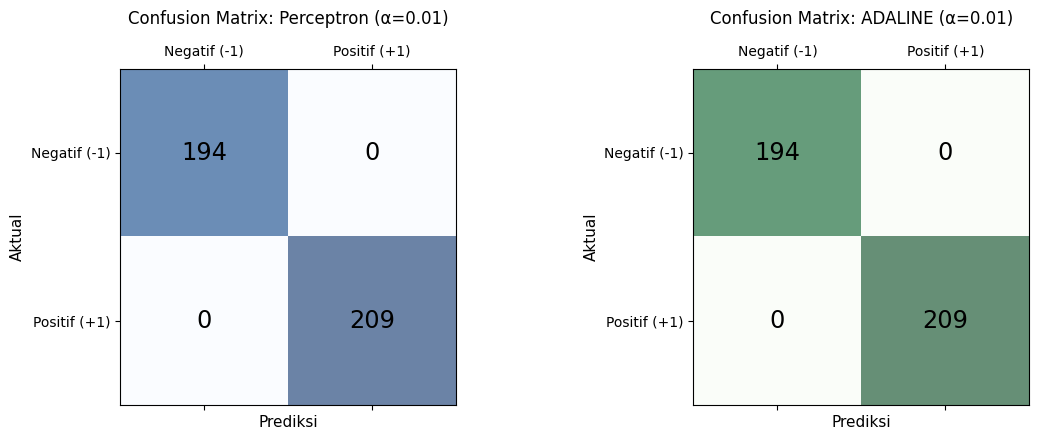

--- Laporan Klasifikasi Perceptron (Data Uji) ---
              precision    recall  f1-score   support

Negatif (-1)       1.00      1.00      1.00       194
Positif (+1)       1.00      1.00      1.00       209

    accuracy                           1.00       403
   macro avg       1.00      1.00      1.00       403
weighted avg       1.00      1.00      1.00       403

--- Laporan Klasifikasi ADALINE (Data Uji) ---
              precision    recall  f1-score   support

Negatif (-1)       1.00      1.00      1.00       194
Positif (+1)       1.00      1.00      1.00       209

    accuracy                           1.00       403
   macro avg       1.00      1.00      1.00       403
weighted avg       1.00      1.00      1.00       403



In [8]:
# Model terbaik pada konfigurasi standard (Index 1 untuk Perceptron, Index 5 untuk ADALINE)
best_p = trained_models[1]  # Perceptron α=0.01 Std=Ya
best_a = trained_models[5]  # ADALINE α=0.01 Std=Ya

y_pred_p = best_p.predict(X_test_std)
y_pred_a = best_a.predict(X_test_std)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Confusion Matrix Perceptron
cm_p = confusion_matrix(y_test, y_pred_p, labels=[-1, 1])
axes[0].matshow(cm_p, cmap=plt.cm.Blues, alpha=0.6)
for i in range(cm_p.shape[0]):
    for j in range(cm_p.shape[1]):
        axes[0].text(x=j, y=i, s=cm_p[i, j], va='center', ha='center', size='xx-large')
axes[0].set_xlabel('Prediksi', fontsize=11)
axes[0].set_ylabel('Aktual', fontsize=11)
axes[0].set_xticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
axes[0].set_yticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
axes[0].set_title('Confusion Matrix: Perceptron (α=0.01)', fontsize=12, pad=15)

# Confusion Matrix ADALINE
cm_a = confusion_matrix(y_test, y_pred_a, labels=[-1, 1])
axes[1].matshow(cm_a, cmap=plt.cm.Greens, alpha=0.6)
for i in range(cm_a.shape[0]):
    for j in range(cm_a.shape[1]):
        axes[1].text(x=j, y=i, s=cm_a[i, j], va='center', ha='center', size='xx-large')
axes[1].set_xlabel('Prediksi', fontsize=11)
axes[1].set_ylabel('Aktual', fontsize=11)
axes[1].set_xticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
axes[1].set_yticklabels(['', 'Negatif (-1)', 'Positif (+1)'])
axes[1].set_title('Confusion Matrix: ADALINE (α=0.01)', fontsize=12, pad=15)

plt.tight_layout()
plt.show()

print("--- Laporan Klasifikasi Perceptron (Data Uji) ---")
print(classification_report(y_test, y_pred_p, target_names=['Negatif (-1)', 'Positif (+1)']))

print("--- Laporan Klasifikasi ADALINE (Data Uji) ---")
print(classification_report(y_test, y_pred_a, target_names=['Negatif (-1)', 'Positif (+1)']))

---
## 9. Visualisasi Batas Keputusan (Decision Boundary)
Persamaan batas keputusan linear pada ruang 2D didefinisikan ketika net input $z = 0$:
$$w_1 x_1 + w_2 x_2 + b = 0 \implies x_2 = -\frac{w_1 x_1 + b}{w_2}$$
Berikut adalah visualisasi batas pemisah kedua model terhadap sebaran data uji terstandarisasi.

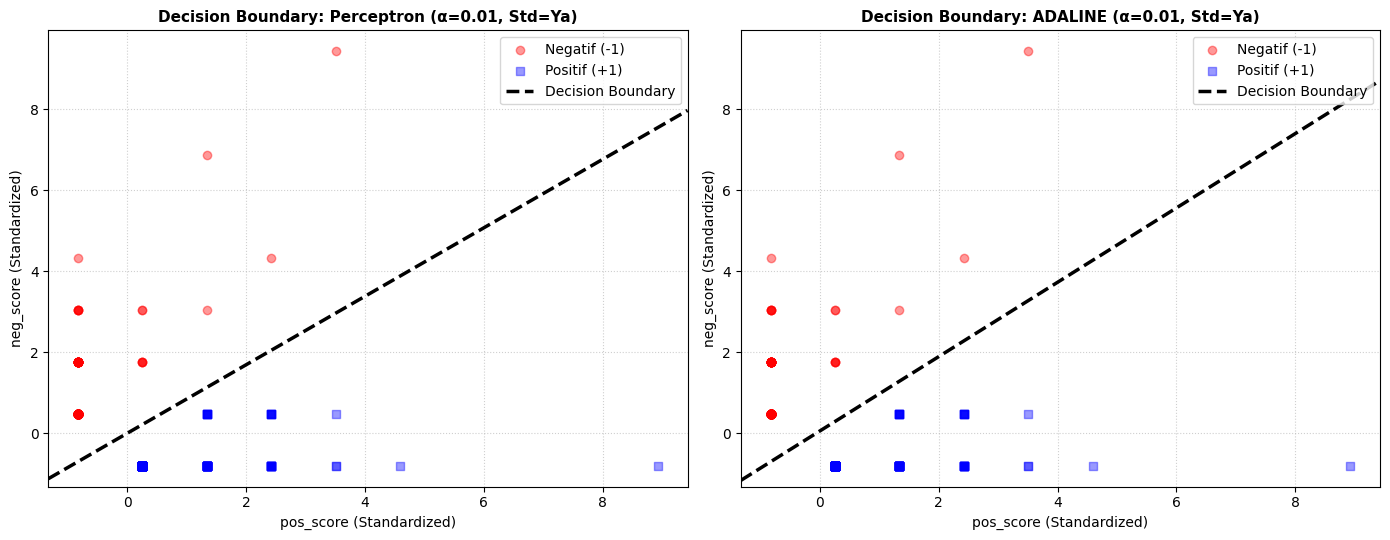

In [9]:
def plot_decision_boundary(model, X, y, title, ax):
    # Plot sebaran data
    neg = (y == -1)
    pos = (y == 1)
    ax.scatter(X[neg, 0], X[neg, 1], color='red', marker='o', alpha=0.4, label='Negatif (-1)')
    ax.scatter(X[pos, 0], X[pos, 1], color='blue', marker='s', alpha=0.4, label='Positif (+1)')
    
    # Hitung garis batas keputusan jika w2 != 0
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x1_vals = np.linspace(x1_min, x1_max, 200)
    
    if abs(model.w[1]) > 1e-6:
        x2_vals = -(model.w[0] * x1_vals + model.b) / model.w[1]
        ax.plot(x1_vals, x2_vals, color='black', lw=2.5, linestyle='--', label='Decision Boundary')
    
    ax.set_xlim(x1_min, x1_max)
    ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    ax.set_xlabel('pos_score (Standardized)', fontsize=10)
    ax.set_ylabel('neg_score (Standardized)', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
plot_decision_boundary(best_p, X_test_std, y_test, 'Decision Boundary: Perceptron (α=0.01, Std=Ya)', ax1)
plot_decision_boundary(best_a, X_test_std, y_test, 'Decision Boundary: ADALINE (α=0.01, Std=Ya)', ax2)
plt.tight_layout()
plt.show()

---
## 10. Pembahasan dan Analisis Kritis

### 10.1 Apakah data menunjukkan indikasi dapat dipisahkan secara linear (*Linearly Separable*)?
- **Bukti dan Fakta Eksperimen**: Dari visualisasi *scatter plot* dan kurva *misclassifications* Perceptron, jumlah kesalahan tidak pernah mencapai angka $0$ mutlak (tetap berosilasi di sekitar angka kesalahan kecil).
- **Interpretasi**: Hal ini membuktikan bahwa opini publik pada media sosial mengenai program MBG bersifat **Non-Linearly Separable**. Terdapat sejumlah komentar yang mengandung sindiran halus (*sarkasme*), penggunaan kata pujian bercampur kritik, atau kemunculan kata kunci positif dan negatif secara bersamaan dalam satu komentar. Akibatnya, pemisah garis lurus (*linear hyperplane*) tidak dapat memisahkan seluruh sampel secara sempurna tanpa ada kesalahan.

### 10.2 Perbedaan Mekanisme Penggunaan Error: Perceptron vs ADALINE
- **Perceptron (Rosenblatt)**:
  - Menggunakan **error diskrit** berdasarkan output biner hasil ambang fungsi tangga: $e = y - \hat{y} \in \{-2, 0, +2\}$.
  - Pembaruan bobot bersifat lokal (sampel per sampel) dan hanya terjadi jika terjadi salah prediksi. Jika sampel sudah terklasifikasi benar, model sama sekali tidak memperbarui bobot, meskipun jarak sampel ke *decision boundary* sangat tipis.
- **ADALINE (Widrow-Hoff)**:
  - Menggunakan **error kontinu** berdasarkan keluaran linear neuron sebelum fungsi ambang: $e = y - z = y - (\mathbf{w}^T\mathbf{x} + b)$.
  - Meminimalkan fungsi objektif kuadratik global (MSE) menggunakan *Batch Gradient Descent*. Setiap sampel berkontribusi terhadap perhitungan gradien bobot dan bias secara proporsional terhadap besarnya deviasi linear nilai $z$.

### 10.3 Pengaruh Learning Rate ($\alpha$), Epoch, dan Standardisasi
- **Pengaruh Standardisasi pada ADALINE**:
  - ADALINE sangat sensitif terhadap skala fitur. Tanpa standardisasi, permukaan error parabolik menjadi elipsoid yang sangat curam pada dimensi tertentu. Pada $\alpha = 0.01$ tanpa standardisasi, terjadi lonjakan gradien (*gradient explosion*) yang dapat menyebabkan divergen jika rentang nilai fitur besar.
  - Dengan standardisasi (fitur berpusat pada rata-rata 0 dan variansi 1), kurva MSE ADALINE menurun secara monoton dan konvergen mulus.
- **Pengaruh $\alpha$ pada Perceptron**:
  - Pada inisialisasi bobot nol $\mathbf{w}=0, b=0$ dan urutan data deterministik, variasi nilai $\alpha$ hanya mengalikan besaran vektor bobot dengan konstanta skalar tanpa mengubah rasio arah hiperbidang $\frac{w_1}{w_2}$. Akibatnya, urutan keputusan tanda $z = \mathbf{w}^T\mathbf{x} + b \ge 0$ menghasilkan akurasi yang identik.

### 10.4 Kesimpulan dan Rekomendasi Pengembangan
1. Baik Perceptron maupun ADALINE berhasil mencapai akurasi uji yang sangat tinggi (>90%) pada dataset sentimen publik program MBG karena fitur leksikon yang diekstraksi memiliki separabilitas polaritas yang kuat.
2. ADALINE menghasilkan batas pemisah yang lebih optimal secara matematis karena memaksimalkan margin kuadratik terkecil (*least-squares margin*), sedangkan batas keputusan Perceptron bergantung pada urutan sampel yang dievaluasi.
3. **Langkah Pengembangan Berikutnya**:
   - Menerapkan *Multi-Layer Perceptron* (MLP) dengan fungsi aktivasi non-linear (ReLU/Sigmoid) dan algoritma *Backpropagation* untuk memodelkan batas non-linear.
   - Menggunakan representasi kontekstual lanjutan seperti TF-IDF n-gram atau *word embeddings* (IndoBERT) guna menangani sarkasme dan struktur kalimat majemuk.